
# PROG8431 - Problem Analysis Workshop B
## K-Means Clustering - Group 7

### Team Members
1. Sukhchain Singh (9111541)
2. Preethi (9125985)
3. Arya (9084843)

### Research Question

Can K-means clustering identify meaningful groups of daily bike rental demand based on temperature and total rentals, and what can these groups tell us about seasonal rental patterns?

### Project Overview

In our previous workshop, we used statistical tests to compare bike rental demand between Winter and Summer.

In this workshop, we will use K-means clustering to find groups of similar days based on temperature and total daily rentals.

K-means is an unsupervised learning method. This means we do not provide the model with predefined group labels. Instead, the algorithm groups days based on how similar their selected numerical values are.

After forming the clusters, we will examine other information, such as season, humidity, wind speed and working days, to better understand each group.

Our goal is to discover useful patterns that may help bike-sharing companies understand historical demand and plan their operations.

This project is about finding patterns, not predicting future rental counts.


In [1]:

# Import libraries for Workshop B

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

print("Libraries imported successfully.")


Libraries imported successfully.


In [3]:

# Load our existing bike-sharing dataset

from pathlib import Path
import pandas as pd

# Step 1: Check where Jupyter is running
current_folder = Path.cwd()
print("Current working folder:", current_folder)

# Step 2: Search the current folder and its parent folders
search_folders = [current_folder, *current_folder.parents]

csv_path = None

for folder in search_folders:
    possible_path = folder / "data" / "day.csv"

    if possible_path.is_file():
        csv_path = possible_path
        break

# Step 3: Make sure the dataset was found
if csv_path is None:
    raise FileNotFoundError(
        "Could not find data/day.csv. "
        "Please check your VS Code project folder."
    )

# Step 4: Load the dataset
df = pd.read_csv(csv_path)

# Step 5: Display basic information
print("\nDataset loaded successfully!")
print("Dataset location:", csv_path)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Current working folder: d:\Data Analysis, Mathematics\week 4\presentation\Data_Analysis_Presentation1\src\Workshop_B_KMeans

Dataset loaded successfully!
Dataset location: d:\Data Analysis, Mathematics\week 4\presentation\Data_Analysis_Presentation1\data\day.csv
Total rows: 731
Total columns: 16

First five rows:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344,0.364,0.806,0.160,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363,0.354,0.696,0.249,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196,0.189,0.437,0.248,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200,0.212,0.590,0.160,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.227,0.229,0.437,0.187,82,1518,1600



Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']



## 2. Data Validation and Cleaning

Before using K-means clustering, we need to make sure our dataset is ready for analysis.

Our dataset contains 731 daily bike rental records from 2011 and 2012.

We will check:

1. **Missing values:** Are any important values missing?
2. **Duplicate dates:** Does the same day appear more than once?
3. **Data types:** Are dates and numerical values stored correctly?
4. **Season codes:** Are the season values valid?
5. **Rental totals:** Does the total number of rentals match casual plus registered rentals?
6. **Numerical ranges:** Are temperature, humidity and rental values within their expected ranges?

These checks are important because incorrect or missing values could affect how K-means groups our data.

We will only make changes if they are needed, and we will explain any changes we make.


In [4]:

# Step 2: Examine and validate our dataset

# Work on a copy to keep the original data unchanged
bike_df = df.copy()

# 1. Check data types
print("1. DATA TYPES")
print(bike_df.dtypes)

# 2. Check missing values
print("\n2. MISSING VALUES")
print(bike_df.isna().sum())
print("Total missing values:", bike_df.isna().sum().sum())

# 3. Check duplicate records and dates
print("\n3. DUPLICATES")
print("Duplicate rows:", bike_df.duplicated().sum())
print("Duplicate dates:", bike_df["dteday"].duplicated().sum())

# 4. Check season codes
print("\n4. SEASON CODES")
print(bike_df["season"].value_counts().sort_index())

invalid_seasons = ~bike_df["season"].isin([1, 2, 3, 4])
print("Invalid season codes:", invalid_seasons.sum())

# 5. Verify rental totals
print("\n5. RENTAL TOTALS")
incorrect_totals = (
    bike_df["casual"] + bike_df["registered"]
    != bike_df["cnt"]
)
print("Incorrect rental totals:", incorrect_totals.sum())

# 6. Check numerical ranges
print("\n6. NUMERICAL RANGES")
display(
    bike_df[
        ["temp", "atemp", "hum", "windspeed", "cnt"]
    ].agg(["min", "max", "mean", "std"]).round(3)
)

# 7. Validate expected ranges
print("\n7. RANGE VALIDATION")

for column in ["temp", "atemp", "hum", "windspeed"]:
    invalid_count = (~bike_df[column].between(0, 1)).sum()
    print(f"{column}: {invalid_count} values outside [0, 1]")

print("Negative rental counts:", (bike_df["cnt"] < 0).sum())


1. DATA TYPES
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

2. MISSING VALUES
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Total missing values: 0

3. DUPLICATES
Duplicate rows: 0
Duplicate dates: 0

4. SEASON CODES
season
1    181
2    184
3    188
4    178
Name: count, dtype: int64
Invalid season codes: 0

5. RENTAL TOTALS
Incorrect rental totals: 0

6. NUMERICAL RANGES


,temp,atemp,hum,windspeed,cnt
min,0.059,0.079,0.000,0.022,22.000
max,0.862,0.841,0.972,0.507,8714.000
mean,0.495,0.474,0.628,0.190,4504.349
std,0.183,0.163,0.142,0.077,1937.211



7. RANGE VALIDATION
temp: 0 values outside [0, 1]
atemp: 0 values outside [0, 1]
hum: 0 values outside [0, 1]
windspeed: 0 values outside [0, 1]
Negative rental counts: 0


In [5]:

# Final data validation and preparation

# Step 1: Convert dates from text to datetime
bike_df["dteday"] = pd.to_datetime(
    bike_df["dteday"],
    errors="raise"
)

# Step 2: Add readable season names
season_names = {
    1: "Winter",
    2: "Spring",
    3: "Summer",
    4: "Fall"
}

bike_df["Season_Name"] = bike_df["season"].map(season_names)

# Step 3: Summarize our data quality checks
print("FINAL DATA QUALITY REPORT")
print("-" * 35)

print("Total records:", len(bike_df))
print("Missing values:", bike_df.isna().sum().sum())
print("Duplicate rows:", bike_df.duplicated().sum())
print("Duplicate dates:", bike_df["dteday"].duplicated().sum())
print("Date data type:", bike_df["dteday"].dtype)

print("\nRecords by season:")
print(bike_df["Season_Name"].value_counts())

# Step 4: Check the prepared data
print("\nPrepared dataset preview:")
display(
    bike_df[
        ["dteday", "Season_Name", "temp", "cnt"]
    ].head()
)


FINAL DATA QUALITY REPORT
-----------------------------------
Total records: 731
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0
Date data type: datetime64[us]

Records by season:
Season_Name
Summer    188
Spring    184
Winter    181
Fall      178
Name: count, dtype: int64

Prepared dataset preview:


,dteday,Season_Name,temp,cnt
0,2011-01-01,Winter,0.344,985
1,2011-01-02,Winter,0.363,801
2,2011-01-03,Winter,0.196,1349
3,2011-01-04,Winter,0.200,1562
4,2011-01-05,Winter,0.227,1600



### Data Validation and Cleaning Results

After checking our bike-sharing dataset, we found that it contains 731 daily records from 2011 and 2012.

Our results showed:

- No missing values.
- No duplicate rows or duplicate dates.
- No incorrect rental totals.
- No negative rental counts.
- Temperature, humidity and wind speed values were within their expected normalized ranges.

We converted the date column from text into datetime format so Python can work with the dates correctly.

We also converted the season codes into readable names: Winter, Spring, Summer and Fall.

The dataset contains 181 Winter days, 184 Spring days, 188 Summer days and 178 Fall days.

Since we did not find missing values or duplicate records, we did not need to remove any rows.

We kept the original dataset unchanged and prepared a separate copy for our analysis.

We will examine unusually high and low values next before deciding whether any further cleaning is necessary.

This is important because K-means uses distances between data points. Incorrect values or unusual observations can affect where the cluster centres are placed.



## 3. Exploratory Data Analysis and Outlier Detection

### Why Are We Checking for Outliers?

Before applying K-means clustering, we want to understand how our numerical data is distributed.

An outlier is a value that is unusually far from most other values.

We will examine two variables:

1. **Temperature (`temp`):** The normalized temperature recorded each day.
2. **Total Rentals (`cnt`):** The total number of bikes rented each day.

We selected these variables because they are relevant to our research question about temperature and daily rental demand.

We will use boxplots to identify possible outliers.

This is important because K-means calculates distances between data points. Extreme values can influence the cluster centres and the final groups.

We will also calculate the Interquartile Range (IQR) to identify potential outliers using a numerical rule.

We will not automatically remove outliers because unusual rental days may contain useful information.


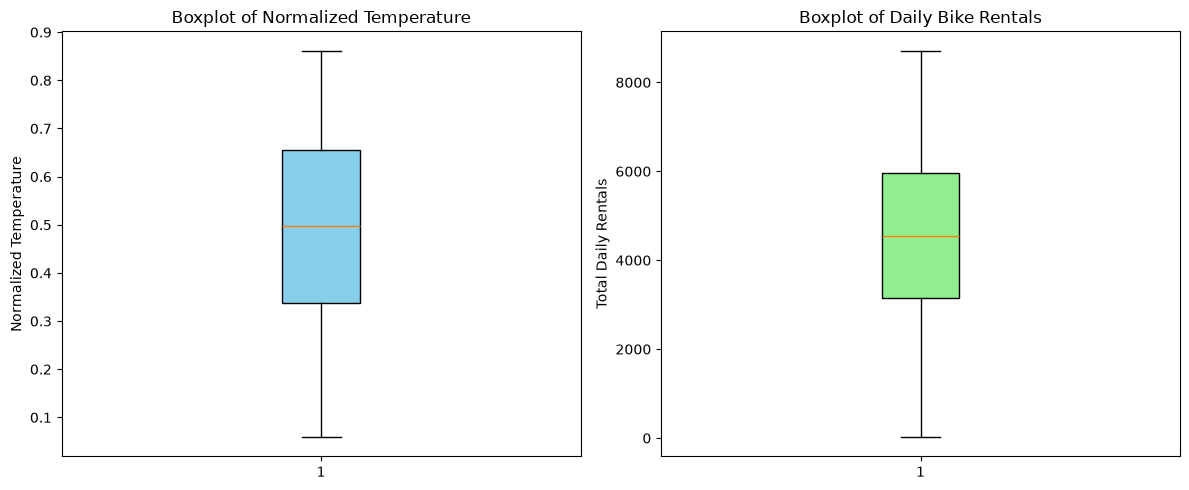

OUTLIER ANALYSIS USING IQR
----------------------------------------

Variable: temp
Q1: 0.337
Q3: 0.655
IQR: 0.318
Lower boundary: -0.140
Upper boundary: 1.133
Potential outliers: 0

Variable: cnt
Q1: 3152.000
Q3: 5956.000
IQR: 2804.000
Lower boundary: -1054.000
Upper boundary: 10162.000
Potential outliers: 0


In [6]:

# Step 3: Explore outliers using boxplots and IQR

# 1. Create boxplots for our two selected variables
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Temperature boxplot
axes[0].boxplot(
    bike_df["temp"].dropna(),
    patch_artist=True,
    boxprops={"facecolor": "skyblue"}
)
axes[0].set_title("Boxplot of Normalized Temperature")
axes[0].set_ylabel("Normalized Temperature")

# Total rentals boxplot
axes[1].boxplot(
    bike_df["cnt"].dropna(),
    patch_artist=True,
    boxprops={"facecolor": "lightgreen"}
)
axes[1].set_title("Boxplot of Daily Bike Rentals")
axes[1].set_ylabel("Total Daily Rentals")

plt.tight_layout()
plt.show()


# 2. Detect possible outliers using IQR
print("OUTLIER ANALYSIS USING IQR")
print("-" * 40)

for column in ["temp", "cnt"]:

    # Find the first and third quartiles
    Q1 = bike_df[column].quantile(0.25)
    Q3 = bike_df[column].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count values outside the boundaries
    outliers = bike_df[
        (bike_df[column] < lower_bound) |
        (bike_df[column] > upper_bound)
    ]

    print(f"\nVariable: {column}")
    print(f"Q1: {Q1:.3f}")
    print(f"Q3: {Q3:.3f}")
    print(f"IQR: {IQR:.3f}")
    print(f"Lower boundary: {lower_bound:.3f}")
    print(f"Upper boundary: {upper_bound:.3f}")
    print(f"Potential outliers: {len(outliers)}")



### Outlier Analysis Results and Interpretation

We used boxplots and the Interquartile Range (IQR) method to examine possible outliers in temperature and daily bike rentals.

**Temperature (`temp`):**
- Q1 = 0.337
- Q3 = 0.655
- IQR = 0.318
- Potential outliers = 0

**Daily Bike Rentals (`cnt`):**
- Q1 = 3,152
- Q3 = 5,956
- IQR = 2,804
- Potential outliers = 0

### What Did We Find?

Both boxplots showed that the data values were within the IQR outlier boundaries.

The middle 50% of daily rental counts were between 3,152 and 5,956. The middle 50% of normalized temperatures were between 0.337 and 0.655.

Although some days had very high or very low rentals, none were flagged as outliers by the 1.5 × IQR rule.

### Our Decision

We decided to keep all 731 records because we did not find any invalid values or IQR outliers in our selected variables.

Keeping all observations allows our clustering analysis to include different types of rental days.

### Why Is This Important for K-Means?

K-means groups observations based on their distances from cluster centres.

Values far away from the others can influence where those centres are placed.

Checking for outliers before clustering helps us understand whether unusually large or small values might affect the results.

We will now select our clustering variables and prepare them for standardization.



## 4. Selection of Clustering Variables

### Which Variables Did We Choose?

For K-means clustering, we selected two numerical variables:

1. **Normalized Temperature (`temp`)**
2. **Total Daily Bike Rentals (`cnt`)**

### Why Did We Choose These Variables?

Our research question focuses on understanding how temperature and season are related to bike rental demand.

Temperature describes the weather conditions, while total rentals show how many bikes people rented.

By using both variables, K-means can group days with similar temperature and rental demand patterns.

For example, clustering may identify cooler days with lower demand or warmer days with higher demand.

These are only possible patterns. We will examine the actual results before naming the clusters.

### Why Did We Not Use Season to Create Clusters?

Season is a categorical variable, meaning it represents groups such as Winter, Spring, Summer and Fall.

The numbers 1, 2, 3 and 4 are category codes, not meaningful numerical distances.

K-means works with distances between numerical values, so we selected temperature and rental counts instead.

After clustering, we will use season, humidity, wind speed and other available columns to describe and better understand the groups.

### What Can We Learn?

We want to discover different types of bike rental days rather than only compare predefined seasons.

Because daily rentals are used to create the clusters, differences in rental demand between clusters are partly expected. Our goal is to describe these historical patterns, not predict future rentals or prove that temperature causes demand changes.


SELECTED CLUSTERING FEATURES
-----------------------------------


,temp,cnt
count,731.000,731.000
mean,0.495,4504.349
std,0.183,1937.211
min,0.059,22.000
25%,0.337,3152.000
50%,0.498,4548.000
75%,0.655,5956.000
max,0.862,8714.000


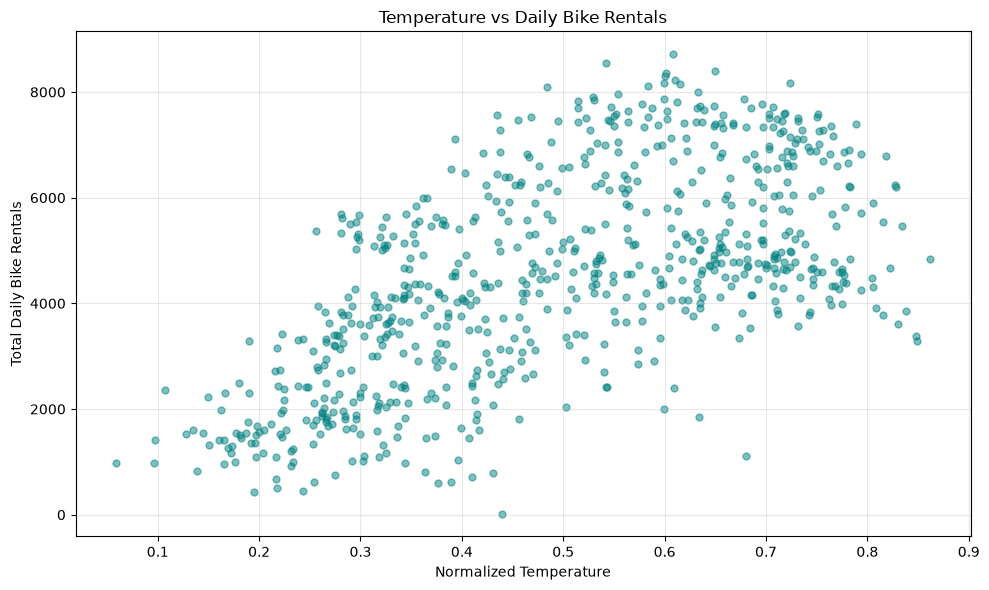

Rows prepared for clustering: 731
Features selected: ['temp', 'cnt']


In [7]:

# Step 4: Explore our selected clustering variables

# Step 1: Create a separate dataset with only two features
cluster_features = bike_df[["temp", "cnt"]].copy()

# Step 2: Display descriptive statistics
print("SELECTED CLUSTERING FEATURES")
print("-" * 35)

display(cluster_features.describe().round(3))

# Step 3: Create a scatterplot
plt.figure(figsize=(10, 6))

plt.scatter(
    cluster_features["temp"],
    cluster_features["cnt"],
    alpha=0.5,
    color="teal",
    s=25
)

plt.title("Temperature vs Daily Bike Rentals")
plt.xlabel("Normalized Temperature")
plt.ylabel("Total Daily Bike Rentals")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 4: Confirm the dataset size
print("Rows prepared for clustering:", len(cluster_features))
print("Features selected:", cluster_features.columns.tolist())



### Interpretation of Selected Features and Scatterplot

We selected normalized temperature (`temp`) and total daily bike rentals (`cnt`) as our two clustering variables.

Our dataset contains 731 observations for both variables.

The average normalized temperature was 0.495, and the average number of daily bike rentals was approximately 4,504.

The scatterplot shows a generally positive relationship between temperature and daily rentals. As temperature increases, bike rental demand also tends to increase.

However, rental counts vary even when temperatures are similar. This suggests that other factors, such as season, weather conditions and working days, may also be related to demand.

### Why Are These Variables Suitable for K-Means?

Using temperature and rental counts will help us identify groups of days with similar weather and rental demand patterns.

We can then use additional columns from our dataset to understand what makes each cluster different.

Before running K-means, we need to standardize these two variables because their numerical scales are very different.



## 5. Data Standardization

### Why Do We Need Standardization?

K-means clustering groups observations based on the distance between their numerical values.

Our two selected variables have very different scales:

- Temperature (`temp`) ranges from approximately 0.059 to 0.862.
- Daily rentals (`cnt`) range from 22 to 8,714.

Without standardization, the larger rental numbers could dominate the distance calculations.

We will compare two methods from our professor's demonstration:

1. Min-Max Scaling
2. Z-score Standardization

Min-Max scaling transforms values to a range between 0 and 1.

Z-score standardization transforms values based on their mean and standard deviation.

We will examine the results of both methods before deciding which one to use for our final clustering model.


In [8]:

# Step 5: Compare two standardization methods

# Method 1: Min-Max Scaling
def sta01(x):
    return (x - x.min()) / (x.max() - x.min())


# Method 2: Z-score Standardization
def stamn(x):
    return (x - x.mean()) / x.std()


# Apply both methods to our selected features
minmax_data = cluster_features.apply(sta01)
zscore_data = cluster_features.apply(stamn)


# Compare the original and scaled datasets
print("1. ORIGINAL DATA")
display(cluster_features.describe().round(3))

print("\n2. MIN-MAX SCALED DATA")
display(minmax_data.describe().round(3))

print("\n3. Z-SCORE STANDARDIZED DATA")
display(zscore_data.describe().round(3))


# Check the results
print("\nSCALING VERIFICATION")
print("-" * 40)

print("Min-Max minimum values:")
print(minmax_data.min().round(3))

print("\nMin-Max maximum values:")
print(minmax_data.max().round(3))

print("\nZ-score means:")
print(zscore_data.mean().round(3))

print("\nZ-score standard deviations:")
print(zscore_data.std().round(3))


1. ORIGINAL DATA


,temp,cnt
count,731.000,731.000
mean,0.495,4504.349
std,0.183,1937.211
min,0.059,22.000
25%,0.337,3152.000
50%,0.498,4548.000
75%,0.655,5956.000
max,0.862,8714.000



2. MIN-MAX SCALED DATA


,temp,cnt
count,731.000,731.000
mean,0.544,0.516
std,0.228,0.223
min,0.000,0.000
25%,0.346,0.360
50%,0.547,0.521
75%,0.743,0.683
max,1.000,1.000



3. Z-SCORE STANDARDIZED DATA


,temp,cnt
count,731.000,731.000
mean,-0.000,-0.000
std,1.000,1.000
min,-2.383,-2.314
25%,-0.865,-0.698
50%,0.016,0.023
75%,0.874,0.749
max,2.001,2.173



SCALING VERIFICATION
----------------------------------------
Min-Max minimum values:
temp   0.000
cnt    0.000
dtype: float64

Min-Max maximum values:
temp   1.000
cnt    1.000
dtype: float64

Z-score means:
temp   -0.000
cnt    -0.000
dtype: float64

Z-score standard deviations:
temp   1.000
cnt    1.000
dtype: float64



### Standardization Results and Final Method Selection

We applied Min-Max scaling and Z-score standardization to our two selected variables: normalized temperature (`temp`) and total daily rentals (`cnt`).

### Min-Max Scaling Results

After applying Min-Max scaling, both variables had a minimum value of 0 and a maximum value of 1.

The standard deviations were:
- Temperature: 0.228
- Daily rentals: 0.223

This method successfully placed both variables within the same range.

### Z-Score Standardization Results

After applying Z-score standardization, both variables had:
- Mean: approximately 0
- Standard deviation: 1

This means both features are measured based on how far their values are from their own averages.

### Which Method Did We Choose?

We decided to use Z-score standardization for our main K-means analysis.

We chose this method because it gives both features the same standard deviation. This helps us compare differences in temperature and rental demand without allowing the original numerical scale to dominate the distance calculations.

Both methods worked correctly, and Min-Max scaling would also be a reasonable choice for our dataset.

Our IQR analysis did not identify any outliers in the selected variables, but this does not mean the data cannot contain unusual observations.

### Why Does This Matter for K-Means?

K-means groups observations by calculating distances between them.

Without scaling, daily rental counts would dominate because their numbers are much larger than the temperature values.

By standardizing both features, we make the distance calculations more balanced.

We will use the Z-score standardized data for the clustering model and keep the original data for interpreting the final clusters.


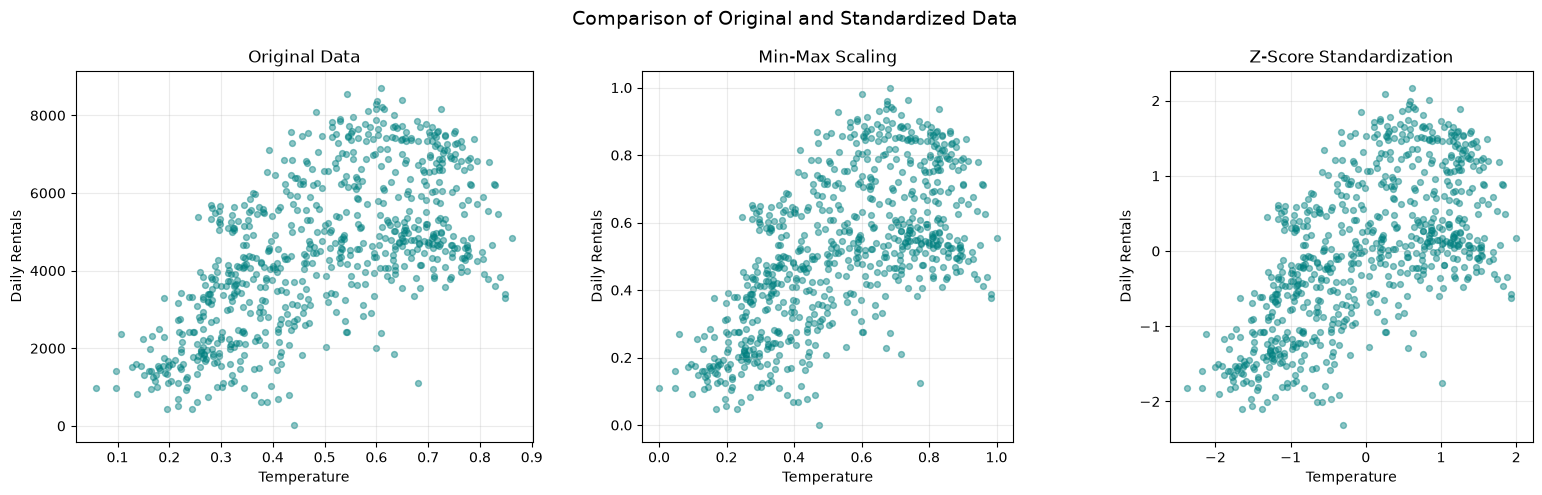

FINAL K-MEANS INPUT
Shape: (731, 2)
Columns: ['temp', 'cnt']
Missing values: 0


,temp,cnt
0,-0.826,-1.817
1,-0.721,-1.912
2,-1.634,-1.629
3,-1.614,-1.519
4,-1.466,-1.499


In [9]:

# Step 5.4: Compare the original and scaled feature spaces

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

datasets = [
    (cluster_features, "Original Data"),
    (minmax_data, "Min-Max Scaling"),
    (zscore_data, "Z-Score Standardization")
]

for ax, (data, title) in zip(axes, datasets):

    ax.scatter(
        data["temp"],
        data["cnt"],
        color="teal",
        alpha=0.45,
        s=18
    )

    ax.set_title(title)
    ax.set_xlabel("Temperature")
    ax.set_ylabel("Daily Rentals")
    ax.grid(alpha=0.25)

# Use the same physical scaling on both axes
# for the two standardized plots.
axes[1].set_aspect("equal", adjustable="box")
axes[2].set_aspect("equal", adjustable="box")

plt.suptitle(
    "Comparison of Original and Standardized Data",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Prepare the final input dataset for Preethi
X_scaled = zscore_data.copy()

print("FINAL K-MEANS INPUT")
print("Shape:", X_scaled.shape)
print("Columns:", X_scaled.columns.tolist())
print("Missing values:", X_scaled.isna().sum().sum())

display(X_scaled.head())



### Comparison of Original and Standardized Data

We created three scatterplots to compare our original data, Min-Max scaled data, and Z-score standardized data.

### Original Data

The original scatterplot shows a generally positive relationship between temperature and daily bike rentals.

However, the numerical scales of our two variables are very different. Temperature values are less than 1, while daily rentals can reach several thousand.

This could cause rental counts to have much more influence on K-means distance calculations.

### Min-Max Scaling

After Min-Max scaling, both temperature and rental counts range from 0 to 1.

The general pattern of the data remains the same, but both features now use a common numerical range.

### Z-Score Standardization

After Z-score standardization, both variables have an average of approximately 0 and a standard deviation of 1.

Values below 0 are below their variable's average, while positive values are above the average.

The scatterplot still shows the same overall relationship, but the values are now measured in standard deviation units.

### Our Final Decision

We selected Z-score standardization for our main clustering analysis because both features have equal standard deviations after scaling.

This allows temperature and daily rentals to contribute to distance calculations on comparable scales.

Min-Max scaling also worked correctly and would be a reasonable alternative.

We have prepared a separate dataset called `X_scaled`, containing 731 observations and two standardized features, with no missing values.

This dataset will be used for K-means clustering in the next section.


In [10]:

# Step 5.5: Final data preparation and validation

# Keep a copy of the standardized features
X_scaled = zscore_data.copy()

# Check that our original and scaled datasets match
assert len(X_scaled) == len(bike_df)
assert X_scaled.shape[1] == 2
assert X_scaled.index.equals(bike_df.index)

# Check for missing and infinite values
assert X_scaled.notna().all().all()
assert np.isfinite(X_scaled.to_numpy()).all()

# Check the standardization results
assert np.allclose(X_scaled.mean(), 0, atol=1e-10)
assert np.allclose(X_scaled.std(), 1, atol=1e-10)

print("FINAL DATA VALIDATION PASSED")
print("-" * 40)

print("Total observations:", len(X_scaled))
print("Clustering features:", X_scaled.columns.tolist())
print("Missing values:", X_scaled.isna().sum().sum())
print("Data ready for K-means:", True)

print("\nFinal standardized dataset:")
display(X_scaled.head())


FINAL DATA VALIDATION PASSED
----------------------------------------
Total observations: 731
Clustering features: ['temp', 'cnt']
Missing values: 0
Data ready for K-means: True

Final standardized dataset:


,temp,cnt
0,-0.826,-1.817
1,-0.721,-1.912
2,-1.634,-1.629
3,-1.614,-1.519
4,-1.466,-1.499



## 6. Prepared Data for K-Means Clustering

### Final Data Preparation Summary

We have completed the data preparation for our K-means clustering analysis.

We started with 731 daily bike rental records from the UCI Bike Sharing Dataset.

We checked the dataset for missing values, duplicates, incorrect rental totals and invalid numerical ranges.

We also examined possible outliers using boxplots and the IQR method. No outliers were identified in our two selected features using the 1.5 × IQR rule.

### Selected Features

We selected two variables:

1. `temp` - Normalized temperature
2. `cnt` - Total daily bike rentals

These variables will help us group days based on their temperature and rental demand.

### Standardization

We compared Min-Max scaling and Z-score standardization.

Both methods successfully scaled our data.

We selected Z-score standardization for our main analysis because it gives both variables a mean of 0 and a standard deviation of 1.

### Final Dataset

Our final dataset is stored in `X_scaled`.

- Observations: 731
- Features: 2
- Missing values: 0
- Infinite values: 0

We also kept `bike_df`, which contains the full prepared dataset, so we can use additional columns when describing the final clusters.

### Next Step: K-Means Clustering

The next step is to use `X_scaled` to run the K-means algorithm.

We will compare different numbers of clusters, examine their centres and sizes, create an elbow chart, and select a suitable final number of clusters based on the results.

We will not decide the final number of clusters before evaluating the different options.
